<a href="https://colab.research.google.com/github/1322vishav/Image-Processing/blob/main/Assignment9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_PATH = '/content/drive/MyDrive/image.jpg'

gray = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError(f"Could not read {IMG_PATH}")

def to_u8(a):
    return np.clip(a, 0, 255).astype(np.uint8)

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)

print("Image shape:", gray.shape)

Mounted at /content/drive
Image shape: (720, 1280)


/tmp/ipykernel_2645/2751590939.py:21: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[2].hist(lbp_img.ravel(), 256, [0, 256])


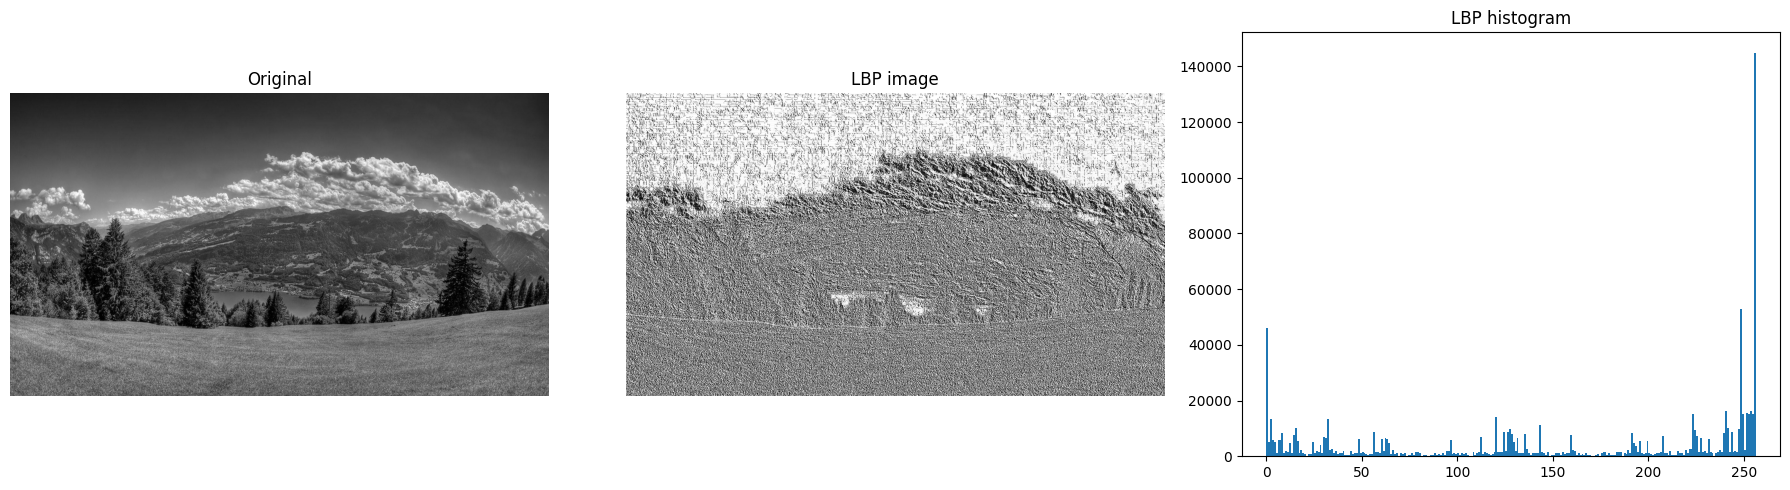

In [2]:
def lbp(img):
    g = img.astype(np.int16)
    h, w = g.shape
    p = np.pad(g, 1, mode='edge')
    neighbours = [p[0:h, 0:w], p[0:h, 1:w + 1], p[0:h, 2:w + 2], p[1:h + 1, 2:w + 2],
                  p[2:h + 2, 2:w + 2], p[2:h + 2, 1:w + 1], p[2:h + 2, 0:w], p[1:h + 1, 0:w]]
    out = np.zeros((h, w), np.uint8)
    for i, n in enumerate(neighbours):
        out |= ((n >= g).astype(np.uint8) << i)
    return out

lbp_img = lbp(gray)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original')
ax[0].axis('off')
ax[1].imshow(lbp_img, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('LBP image')
ax[1].axis('off')
ax[2].hist(lbp_img.ravel(), 256, [0, 256])
ax[2].set_title('LBP histogram')
plt.tight_layout()
plt.show()

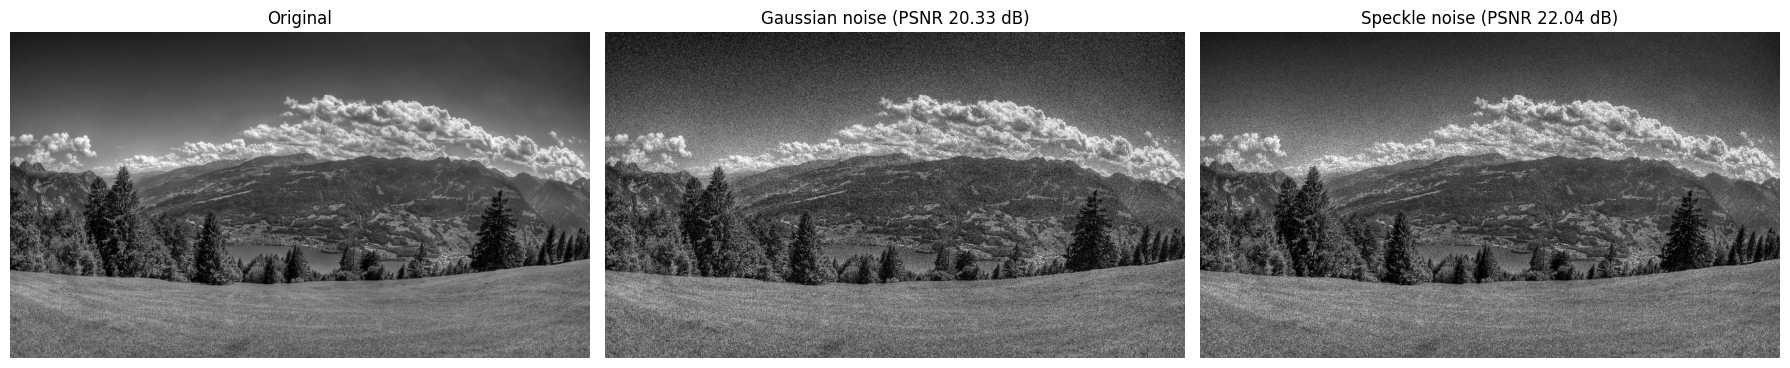

In [3]:
np.random.seed(0)

gauss_noisy = to_u8(gray + np.random.normal(0, 25, gray.shape))
speckle_noisy = to_u8(gray + gray * np.random.normal(0, 0.2, gray.shape))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original')
ax[1].imshow(gauss_noisy, cmap='gray', vmin=0, vmax=255)
ax[1].set_title(f'Gaussian noise (PSNR {psnr(gray, gauss_noisy):.2f} dB)')
ax[2].imshow(speckle_noisy, cmap='gray', vmin=0, vmax=255)
ax[2].set_title(f'Speckle noise (PSNR {psnr(gray, speckle_noisy):.2f} dB)')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

In [4]:
def wiener(img, k):
    f = img.astype(np.float64)
    mu = cv2.blur(f, (k, k), borderType=cv2.BORDER_REFLECT)
    mu2 = cv2.blur(f * f, (k, k), borderType=cv2.BORDER_REFLECT)
    var = np.maximum(mu2 - mu ** 2, 0)
    noise_var = var.mean()
    gain = np.maximum(var - noise_var, 0) / np.maximum(var, noise_var + 1e-12)
    return to_u8(mu + gain * (f - mu))

def apply_filters(noisy, k):
    return {
        'Wiener': wiener(noisy, k),
        'Median': cv2.medianBlur(noisy, k),
        'Gaussian': cv2.GaussianBlur(noisy, (k, k), 0),
        'Bilateral': cv2.bilateralFilter(noisy, d=k, sigmaColor=75, sigmaSpace=75)
    }

Window size (3 or 5): 5


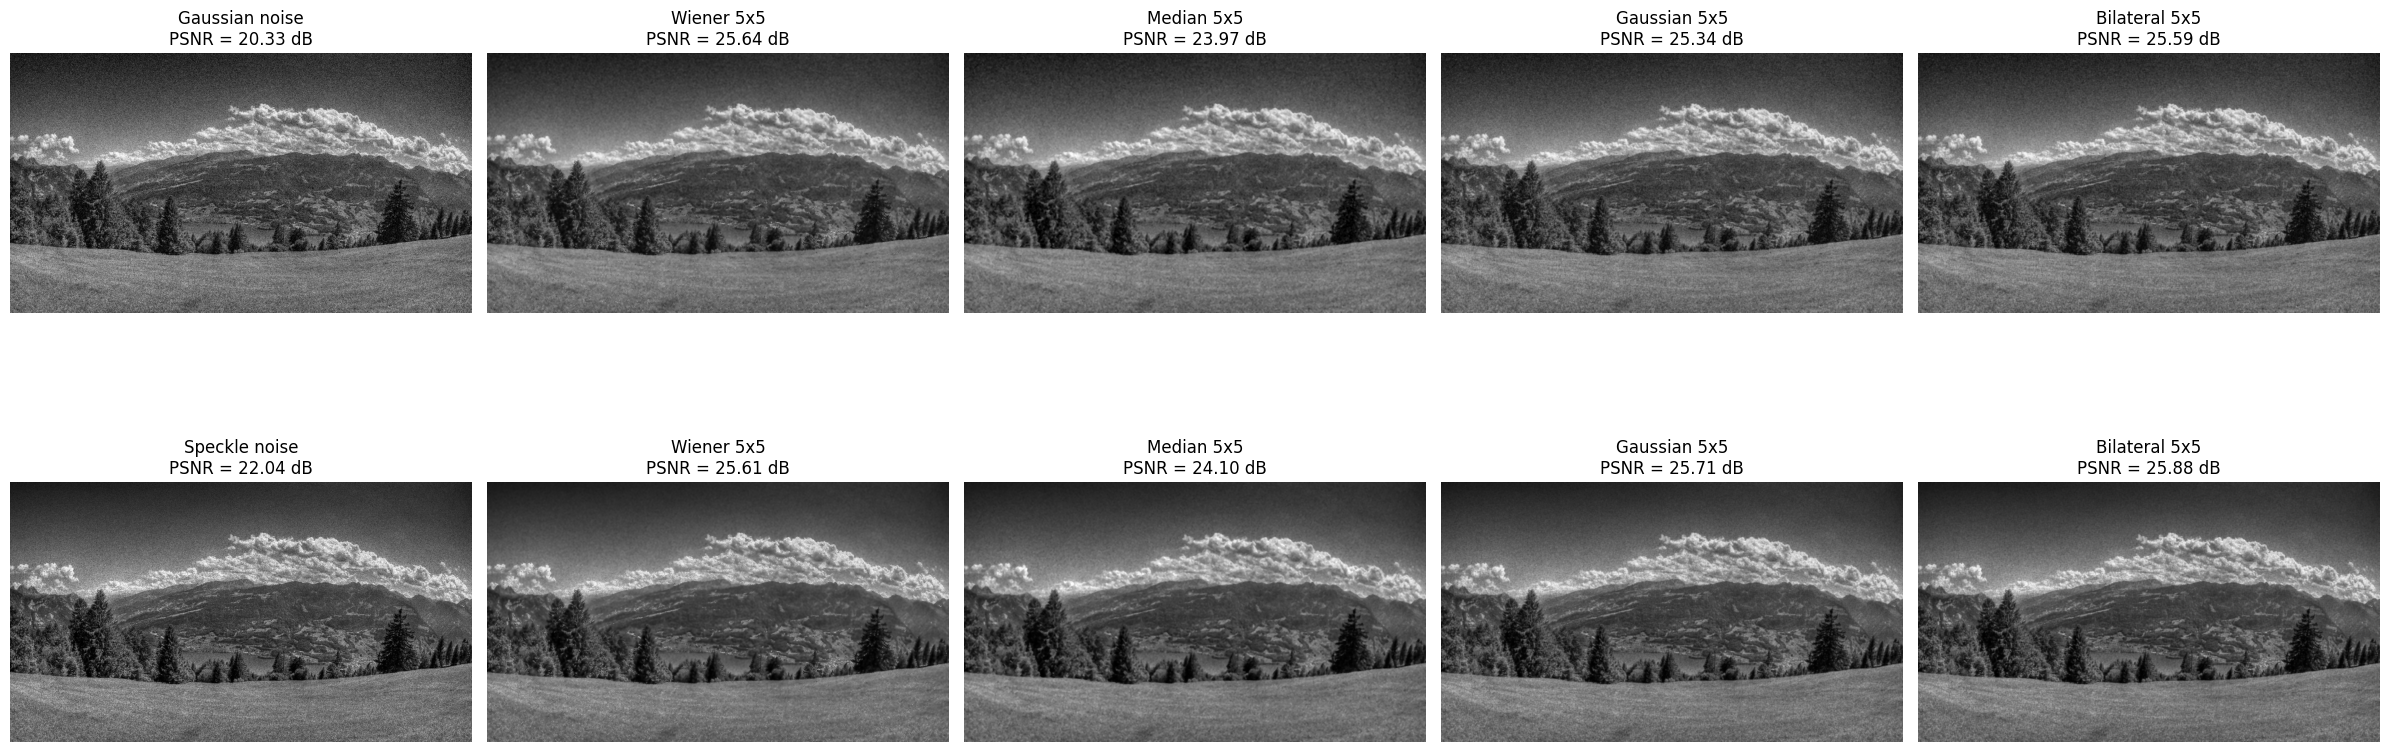

In [5]:
k = int(input("Window size (3 or 5): "))
if k not in (3, 5):
    raise ValueError("Window size must be 3 or 5")

fig, ax = plt.subplots(2, 5, figsize=(24, 10))

for r, (nname, noisy) in enumerate([('Gaussian noise', gauss_noisy), ('Speckle noise', speckle_noisy)]):
    ax[r, 0].imshow(noisy, cmap='gray', vmin=0, vmax=255)
    ax[r, 0].set_title(f'{nname}\nPSNR = {psnr(gray, noisy):.2f} dB')
    ax[r, 0].axis('off')
    for c, (fname, res) in enumerate(apply_filters(noisy, k).items(), start=1):
        ax[r, c].imshow(res, cmap='gray', vmin=0, vmax=255)
        ax[r, c].set_title(f'{fname} {k}x{k}\nPSNR = {psnr(gray, res):.2f} dB')
        ax[r, c].axis('off')

plt.tight_layout()
plt.show()

In [6]:
print(f"{'Noise':<16}{'Noisy':>8}{'Wiener':>9}{'Median':>9}{'Gaussian':>10}{'Bilateral':>11}")
for nname, noisy in [('Gaussian', gauss_noisy), ('Speckle', speckle_noisy)]:
    for kk in (3, 5):
        res = apply_filters(noisy, kk)
        print(f"{nname + f' ({kk}x{kk})':<16}{psnr(gray, noisy):8.2f}"
              f"{psnr(gray, res['Wiener']):9.2f}{psnr(gray, res['Median']):9.2f}"
              f"{psnr(gray, res['Gaussian']):10.2f}{psnr(gray, res['Bilateral']):11.2f}")

Noise              Noisy   Wiener   Median  Gaussian  Bilateral
Gaussian (3x3)     20.33    25.40    24.04     25.52      25.09
Gaussian (5x5)     20.33    25.64    23.97     25.34      25.59
Speckle (3x3)      22.04    25.58    24.63     26.26      26.03
Speckle (5x5)      22.04    25.61    24.10     25.71      25.88
